##### Feladat (Példatár 5.1)

Az alábbi egyenes rúd terhelése az $A$ keresztmetszetben működő $M_1 = 2 ~\mathrm{Nm}$ nagyságú nyomaték. A tartó hajlítómerevsége $IE = 150 ~\mathrm{Nm^2}$, az $AB$ és $BC$ szakaszok hossza $L = 1 ~\mathrm{m}$.

Adatok: $M_1 = 2 ~\mathrm{Nm}$, $IE = 150 ~\mathrm{Nm^2}$, $L = 1 ~\mathrm{m}$, $E = 200 ~\mathrm{GPa}$.

Feladatok:

a) A $BC$ szakasz maximális lehajlása és annak helye?

b) Az $A$, $B$, $C$ keresztmetszetek szögelfordulása és az $A$ keresztmetszet lehajlása?

c) Mekkora $d$ átmérőjű kör keresztmetszetű acélból ($E = 200 ~\mathrm{GPa}$) készítsük a tartót, hogy az $A$ keresztmetszet lehajlása $10 ~\mathrm{mm}$ legyen?

<img src="img/01.jpg" alt="Feladat" width=450px>

##### Csomagok importálása

In [1]:
import numpy as np # Numerikus számítások
import matplotlib.pyplot as plt # Ábrázolás
plt.rcParams['mathtext.fontset'] = 'cm' # Betűtípus az ábrákon
plt.rcParams['font.family'] = 'serif' # Betűtípus az ábrákon
plt.rcParams['font.serif'] = ['cmr10'] # Betűtípus az ábrákon
plt.rcParams['axes.formatter.use_mathtext'] = True # Betűtípus az ábrákon
plt.rcParams['axes.unicode_minus'] = False # Betűtípus az ábrákon
from IPython.display import display, Math, Latex # Szép kimenet Jupyter notebookban
import sympy as sp # Szimbólikus számítások
from sympy import latex # Szép kimenet Jupyter notebookban
sp.init_printing() # Szép kimenet Jupyter notebookban

##### Adatok

In [2]:
M_1_data = 2 # Nm
IE_data = 150 # Nm^2
L_data = 1 # m
E_data = 200 # GPa
w_A_data = -10 # mm (lefelé)

# Átváltás N, mm, MPa rendszerbe
M_1_data = M_1_data * 10**3 # Nmm
IE_data = IE_data * 10**6 # Nmm^2
L_data = L_data * 10**3 # mm
E_data = E_data * 10**3 # MPa

In [3]:
M_1, IE, L, E = sp.symbols('M_1, IE, L, E', positive=True)
w_A_c = sp.Symbol('w_A', negative=True) # Előírt lehajlás (c feladat)
x = sp.Symbol('x')

In [4]:
data = [(M_1, M_1_data),
        (IE, IE_data),
        (L, L_data),
        (E, E_data),
        (w_A_c, w_A_data)]

#### a) A $BC$ szakasz maximális lehajlása és annak helye

##### Rugalmas szál differenciálegyenlete

$$-IE \cdot w''(x) = M_h(x)$$

ahol:
- $w(x)$: a lehajlásfüggvény,
- $IE$: a hajlítómerevség,
- $M_h(x)$: a hajlítónyomatéki függvény.

Másodrendű közönséges differenciálegyenlet, így szakaszonként 2 peremfeltétel kell, továbbá szükség van az $M_h(x)$ hajlítónyomatéki függvényre!

##### Reakcióerők

<img src="img/02.jpg" alt="Feladat" width=450px>

In [5]:
F_B, F_C = sp.symbols('F_B, F_C') # Ismeretlen reakcióerők

# y irányú erő egyensúly
eq1 = F_B + F_C
display(Math(rf'\sum F_y = 0 \quad \longrightarrow \quad {latex(eq1)} = 0'))

# B pontra számított nyomatéki egyensúly
eq2 = M_1 + F_C*L
display(Math(rf'\sum M_B = 0 \quad \longrightarrow \quad {latex(eq2)} = 0'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [6]:
# Rendszer megoldása
sol = sp.solve([eq1, eq2], [F_B, F_C])

F_B_sol = sol[F_B]
display(Math(rf'F_B = {latex(F_B_sol)} = {latex(F_B_sol.subs(data))} ~\mathrm{{N}}'))

F_C_sol = sol[F_C]
display(Math(rf'F_C = {latex(F_C_sol)} = {latex(F_C_sol.subs(data))} ~\mathrm{{N}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### Hajlítónyomatéki függvény

Az $x$ tengely a $C$ pontból indul és balra mutat. Az I. szakasz a $BC$ ($x \in [0, L]$), a II. szakasz az $AB$ ($x \in [L, 2L]$) szakasz. A hajlítónyomatékot a $C$ pont felőli oldalról írjuk fel.

In [7]:
# I. szakasz: x ∈ [0, L]
Mh_1 = -F_C_sol * x
display(Math(rf'M_{{h1}}(x) = -F_C \cdot x = {latex(Mh_1)}, \qquad x \in [0, L]'))

# II. szakasz: x ∈ [L, 2L]
Mh_2 = sp.simplify(-F_C_sol * x - F_B_sol * (x - L))
display(Math(rf'M_{{h2}}(x) = -F_C \cdot x - F_B \cdot (x - L) = {latex(Mh_2)}, \qquad x \in [L, 2L]'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### Peremfeltételek

- $C$ pont görgős támasz: $w_1(0) = 0$
- $B$ pont támasz: $w_1(L) = 0$
- folytonosság I. és II. szakasz között:
    - $w_1(L) = w_2(L) = 0$
    - $\varphi_1(L) = \varphi_2(L)$, azaz $w_1'(L) = w_2'(L)$

##### I. szakasz

In [8]:
C_1, C_2 = sp.symbols('C_1, C_2') # Integrálási konstansok

# Első integrálás
int_1 = sp.integrate(Mh_1, x) + C_1
display(Math(rf'-IE \cdot w_1^{{\prime}}(x) = \int M_{{h1}}(x) \, dx = {latex(int_1)}'))

# Második integrálás
int_int_1 = sp.integrate(int_1, x) + C_2
display(Math(rf'-IE \cdot w_1(x) = \iint M_{{h1}}(x) \, dx = {latex(int_int_1)}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [9]:
# Peremfeltételek (a -IE szorzó kiesik)
eq1 = int_int_1.subs(x, 0)
display(Math(rf'w_1(0) = 0 \quad \longrightarrow \quad {latex(eq1)} = 0'))

eq2 = int_int_1.subs(x, L)
display(Math(rf'w_1(L) = 0 \quad \longrightarrow \quad {latex(eq2)} = 0'))

# Rendszer megoldása
sol = sp.solve([eq1, eq2], [C_1, C_2])
C_1_sol = sol[C_1]
C_2_sol = sol[C_2]
display(Math(rf'C_1 = {latex(C_1_sol)}, \qquad C_2 = {latex(C_2_sol)}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### Így az I. szakaszon

In [10]:
# Lehajlásfüggvény
w_1 = (-int_int_1 / IE).subs({C_1: C_1_sol, C_2: C_2_sol})
k_1 = M_1 / (6*L*IE) # Kiemelt szorzó
display(Math(rf'w_1(x) = {latex(w_1)} = {latex(k_1)} \cdot \left( {latex(sp.expand(w_1 / k_1))} \right)'))

# Szögelfordulás-függvény
phi_1 = sp.diff(w_1, x)
display(Math(rf'\varphi_1(x) = w_1^{{\prime}}(x) = {latex(phi_1)} = {latex(k_1)} \cdot \left( {latex(sp.expand(phi_1 / k_1))} \right)'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### II. szakasz

In [11]:
C_3, C_4 = sp.symbols('C_3, C_4') # Integrálási konstansok

# Első integrálás
int_2 = sp.integrate(Mh_2, x) + C_3
display(Math(rf'-IE \cdot w_2^{{\prime}}(x) = \int M_{{h2}}(x) \, dx = {latex(int_2)}'))

# Második integrálás
int_int_2 = sp.integrate(int_2, x) + C_4
display(Math(rf'-IE \cdot w_2(x) = \iint M_{{h2}}(x) \, dx = {latex(int_int_2)}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [12]:
# Lehajlásfüggvény és szögelfordulás-függvény az ismeretlen konstansokkal
w_2 = -int_int_2 / IE
phi_2 = sp.diff(w_2, x)

# Peremfeltételek
eq3 = phi_1.subs(x, L) - phi_2.subs(x, L)
display(Math(rf'w_1^{{\prime}}(L) = w_2^{{\prime}}(L) \quad \longrightarrow \quad {latex(phi_1.subs(x, L))} = {latex(phi_2.subs(x, L))}'))

eq4 = w_2.subs(x, L)
display(Math(rf'w_2(L) = 0 \quad \longrightarrow \quad {latex(eq4)} = 0'))

# Rendszer megoldása
sol = sp.solve([eq3, eq4], [C_3, C_4])
C_3_sol = sol[C_3]
C_4_sol = sol[C_4]
display(Math(rf'C_3 = {latex(C_3_sol)}, \qquad C_4 = {latex(C_4_sol)}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### Így a II. szakaszon

In [13]:
# Lehajlásfüggvény
w_2 = w_2.subs({C_3: C_3_sol, C_4: C_4_sol})
k_2 = M_1 / (6*IE) # Kiemelt szorzó
display(Math(rf'w_2(x) = {latex(w_2)} = {latex(k_2)} \cdot \left( {latex(sp.expand(w_2 / k_2))} \right)'))

# Szögelfordulás-függvény
phi_2 = sp.diff(w_2, x)
k_3 = M_1 / (3*IE) # Kiemelt szorzó
display(Math(rf'\varphi_2(x) = w_2^{{\prime}}(x) = {latex(phi_2)} = {latex(k_3)} \cdot \left( {latex(sp.expand(phi_2 / k_3))} \right)'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### A $BC$ szakasz maximális lehajlása

$w_\mathrm{max}^{BC}$ a $w_1(x)$ függvény szélsőértéke, ahol $w_1'(x^*) = \varphi_1(x^*) = 0$.

In [14]:
# Szélsőérték helye
sol = sp.solve(phi_1, x)
display(Math(rf'\varphi_1(x^*) = 0 \quad \longrightarrow \quad x^* = {latex(sol)}'))

# Csak a pozitív, [0, L] intervallumba eső megoldás kell
x_star = [s for s in sol if s.is_positive][0]
display(Math(rf'x^* = {latex(x_star)} = {latex(round(x_star.subs(data), 3))} ~\mathrm{{mm}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [15]:
# Maximális lehajlás
w_max = sp.simplify(w_1.subs(x, x_star))
display(Math(rf'w_\mathrm{{max}}^{{BC}} = w_1(x^*) = {latex(w_max)} = {latex(round(w_max.subs(data), 4))} ~\mathrm{{mm}}'))

<IPython.core.display.Math object>

#### b) Az $A$, $B$, $C$ keresztmetszetek szögelfordulása és az $A$ keresztmetszet lehajlása

In [16]:
# A keresztmetszet szögelfordulása
phi_A = phi_2.subs(x, 2*L)
display(Math(rf'\varphi_A = \varphi_2(2L) = {latex(phi_A)} = {latex(round(sp.deg(phi_A.subs(data)), 3))}^\circ'))

# B keresztmetszet szögelfordulása
phi_B = phi_1.subs(x, L)
display(Math(rf'\varphi_B = \varphi_2(L) = \varphi_1(L) = {latex(phi_B)} = {latex(round(sp.deg(phi_B.subs(data)), 3))}^\circ'))

# C keresztmetszet szögelfordulása
phi_C = phi_1.subs(x, 0)
display(Math(rf'\varphi_C = \varphi_1(0) = {latex(phi_C)} = {latex(round(sp.deg(phi_C.subs(data)), 3))}^\circ'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [17]:
# A keresztmetszet lehajlása
w_A = w_2.subs(x, 2*L)
display(Math(rf'w_A = w_2(2L) = {latex(w_A)} = {latex(round(w_A.subs(data), 2))} ~\mathrm{{mm}}'))

<IPython.core.display.Math object>

##### Ábrázolás

<img src="img/03.jpg" alt="Feladat" width=500px>

In [18]:
# Numerikus függvények
w_1_num = sp.lambdify(x, w_1.subs(data), modules='numpy')
w_2_num = sp.lambdify(x, w_2.subs(data), modules='numpy')
phi_1_num = sp.lambdify(x, sp.deg(phi_1.subs(data)), modules='numpy')
phi_2_num = sp.lambdify(x, sp.deg(phi_2.subs(data)), modules='numpy')

# x értékek
x_I_vals = np.linspace(0, float(L.subs(data)))
x_II_vals = np.linspace(float(L.subs(data)), float((2*L).subs(data)))

# y értékek
w_1_vals = w_1_num(x_I_vals)
w_2_vals = w_2_num(x_II_vals)
phi_1_vals = phi_1_num(x_I_vals)
phi_2_vals = phi_2_num(x_II_vals)

# Nevezetes pontok
x_star_num = float(x_star.subs(data))
w_max_num = float(w_max.subs(data))

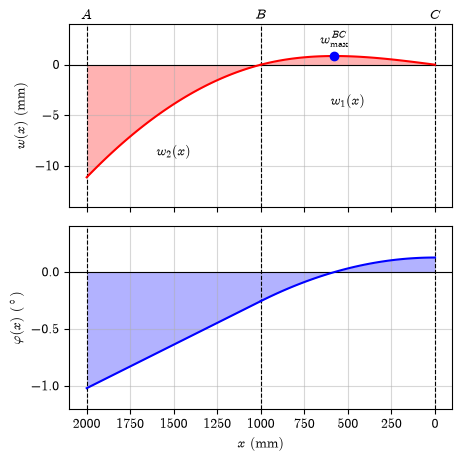

In [19]:
# Ábrázolás
fig, (ax_w, ax_phi) = plt.subplots(2, 1, figsize=(12/2.54, 12/2.54), sharex=True)

# Lehajlás
ax_w.plot(x_I_vals, w_1_vals, color='red', zorder=5)
ax_w.plot(x_II_vals, w_2_vals, color='red', zorder=5)
ax_w.fill_between(x_I_vals, w_1_vals, 0, color='red', alpha=0.3, linewidth=0)
ax_w.fill_between(x_II_vals, w_2_vals, 0, color='red', alpha=0.3, linewidth=0)
ax_w.scatter(x_star_num, w_max_num, color='blue', zorder=6)
ax_w.text(x_star_num, w_max_num + 1.2, r'$w_\mathrm{max}^{BC}$', ha='center')
ax_w.text(float(L.subs(data)) / 2, -4, r'$w_1(x)$', ha='center')
ax_w.text(1.5 * float(L.subs(data)), -9, r'$w_2(x)$', ha='center')
ax_w.axhline(0, color='black', linewidth=0.8)
ax_w.set_ylabel(r'$w(x) ~ \mathrm{(mm)}$')
ax_w.grid(True, alpha=0.5)
ax_w.set_ylim(-14, 4)

# Szögelfordulás
ax_phi.plot(x_I_vals, phi_1_vals, color='blue', zorder=5)
ax_phi.plot(x_II_vals, phi_2_vals, color='blue', zorder=5)
ax_phi.fill_between(x_I_vals, phi_1_vals, 0, color='blue', alpha=0.3, linewidth=0)
ax_phi.fill_between(x_II_vals, phi_2_vals, 0, color='blue', alpha=0.3, linewidth=0)
ax_phi.axhline(0, color='black', linewidth=0.8)
ax_phi.set_xlabel(r'$x ~ \mathrm{(mm)}$')
ax_phi.set_ylabel(r'$\varphi(x) ~ \mathrm{(^\circ)}$')
ax_phi.grid(True, alpha=0.5)
ax_phi.set_ylim(-1.2, 0.4)

# Keresztmetszetek jelölése
for ax in (ax_w, ax_phi):
    for x_p in (0, float(L.subs(data)), float((2*L).subs(data))):
        ax.axvline(x_p, color='black', linestyle='--', linewidth=0.8)
for x_p, nev in zip((0, float(L.subs(data)), float((2*L).subs(data))), ('C', 'B', 'A')):
    ax_w.text(x_p, 4.5, rf'${nev}$', ha='center')

# Az x tengely balra mutat (mint az ábrán)
ax_phi.invert_xaxis()

plt.tight_layout()
plt.savefig('lehajlas_szogelfordulas.pdf')
plt.show()

#### c) A $d$ átmérő, ha az $A$ keresztmetszet lehajlása $10 ~\mathrm{mm}$

Az $A$ keresztmetszet lefelé mozdul el, így $w_A = -10 ~\mathrm{mm}$. Kör keresztmetszet esetén a másodrendű nyomaték:

$$I = \frac{d^4 \pi}{64}$$

In [20]:
I, d = sp.symbols('I, d', positive=True)

# w_A = w_2(2L) egyenletből a másodrendű nyomaték (IE -> I·E)
eq = w_A.subs(IE, I*E) - w_A_c
display(Math(rf'w_A = w_2(2L) = {latex(w_A.subs(IE, I*E))}'))

sol = sp.solve(eq, I)
I_sol = sol[0]
display(Math(rf'I = {latex(I_sol)} = {latex(round(I_sol.subs(data), 3))} ~\mathrm{{mm^4}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [21]:
# Kör keresztmetszet átmérője
eq = d**4 * sp.pi / 64 - I_sol

sol = sp.solve(eq, d)
d_sol = sol[0]
display(Math(rf'd = \sqrt[4]{{\frac{{64 \cdot I}}{{\pi}}}} = \sqrt[4]{{{latex(64 * I_sol / sp.pi)}}} = {latex(round(d_sol.subs(data), 3))} ~\mathrm{{mm}}'))

<IPython.core.display.Math object>